# 04 · Feature Engineering & Model Training
Loads the cleaned dataset saved by `02_eda_cleaning.ipynb` (and the raw snapshot, used for one comparison below).

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import sys
from google.colab import drive

drive.mount('/content/drive')
sys.path.append('/content/drive/MyDrive/Coursera/projects_github/nyc_taxi_2023_v2')

from src.colab_setup import setup_environment
setup_environment()

# Now all your other src modules work cleanly:
from src.api import *
from src.features import *
from src.eda import *
from src.model import *

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

Successfully changed directory to: /content/drive/MyDrive/Coursera/projects_github/nyc_taxi_2023_v2
Environment ready. Project root: /content/drive/MyDrive/Coursera/projects_github/nyc_taxi_2023_v2


In [3]:
df_cleaned = load_processed_data()
df_local = load_raw_data()

Loaded 45,192 cleaned rows
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 17 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   vendorid               50000 non-null  int64  
 1   tpep_pickup_datetime   50000 non-null  object 
 2   tpep_dropoff_datetime  50000 non-null  object 
 3   passenger_count        50000 non-null  float64
 4   trip_distance          50000 non-null  float64
 5   ratecodeid             50000 non-null  float64
 6   store_and_fwd_flag     50000 non-null  object 
 7   pulocationid           50000 non-null  int64  
 8   dolocationid           50000 non-null  int64  
 9   payment_type           50000 non-null  int64  
 10  fare_amount            50000 non-null  float64
 11  extra                  50000 non-null  float64
 12  mta_tax                50000 non-null  float64
 13  tip_amount             50000 non-null  float64
 14  tolls_amount           5000

###Feature engineering

#### Create `mean_distance` column

When deployed, the model will not know the duration of a trip until after the trip occurs, so you cannot train a model that uses this feature. However, you can use the statistics of trips you *do* know to generalize about ones you do not know.

In this step, create a column called `mean_distance` that captures the mean distance for each group of trips that share pickup and dropoff points.

In [4]:
df_cleaned = add_pickup_dropoff(df_cleaned)
df_cleaned['pickup_dropoff'].head(2)

,pickup_dropoff
0,161 141
1,43 237


In [5]:
grouped = route_group_mean(df_cleaned, 'trip_distance')
grouped[:5]

,trip_distance
pickup_dropoff,
1 1,0.125
1 231,14.290
10 102,10.430
10 140,16.110
10 170,13.830


In [6]:
grouped_dict = grouped_to_dict(grouped, 'trip_distance')

In [7]:
df_cleaned = map_mean_distance(df_cleaned, grouped_dict)

# Confirm that it worked
route_example(df_cleaned, 'mean_distance')

,mean_distance
24035,3.001
24560,3.001
27522,3.001
27788,3.001
31723,3.001
35452,3.001
36266,3.001
42321,3.001
43239,3.001
44940,3.001


In [8]:
df_cleaned = add_mean_duration(df_cleaned)

,mean_duration
24035,12.678333
24560,12.678333
27522,12.678333
27788,12.678333
31723,12.678333


In [9]:
df_cleaned = add_day_month(df_cleaned)

,tpep_pickup_datetime,day,month
0,2023-01-01 00:32:10,sunday,jan
1,2023-01-01 00:55:08,sunday,jan
2,2023-01-01 00:25:04,sunday,jan
3,2023-01-01 00:10:29,sunday,jan
4,2023-01-01 00:50:34,sunday,jan


#### Create `rush_hour` column

Define rush hour as:
* Any weekday (not Saturday or Sunday) AND
* Either from 06:00&ndash;10:00 or from 16:00&ndash;20:00

Create a binary `rush_hour` column that contains a 1 if the ride was during rush hour and a 0 if it was not.

In [10]:
df_cleaned = add_rush_hour(df_cleaned)

Distribution of rush_hour trips:


,count
rush_hour,
0,45191
1,1


,tpep_pickup_datetime,day,rush_hour
0,2023-01-01 00:32:10,sunday,0
1,2023-01-01 00:55:08,sunday,0
2,2023-01-01 00:25:04,sunday,0
3,2023-01-01 00:10:29,sunday,0
4,2023-01-01 00:50:34,sunday,0
5,2023-01-01 00:09:22,sunday,0
6,2023-01-01 00:27:12,sunday,0
7,2023-01-01 00:21:44,sunday,0
8,2023-01-01 00:39:42,sunday,0
9,2023-01-01 00:53:01,sunday,0


In [11]:
rush_hour_counts(df_cleaned)

Number of rush hour trips (using shape): 1
Number of rush hour trips (using column sum): 1


In [12]:
# Filter the cleaned DataFrame for rush hour trips
df_rush_hour = filter_rush_hour(df_cleaned)

# Display the filtered DataFrame
display(df_rush_hour)

,vendorid,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,ratecodeid,store_and_fwd_flag,pulocationid,dolocationid,payment_type,...,tolls_amount,improvement_surcharge,total_amount,duration,pickup_dropoff,mean_distance,mean_duration,day,month,rush_hour
43313,2,2022-10-25 07:48:15,2022-10-25 07:48:18,2.0,0.76,5.0,N,132,264,1,...,0.0,0.3,94.56,0.05,132 264,6.995714,15.395238,tuesday,oct,1


In [13]:
df_cleaned.month.value_counts()

,count
month,
jan,45165
dec,24
oct,3


### Understanding the Rush Hour Count

There is only **1 record** matching our weekday rush hour criteria in the dataset.

**Reasoning:**
* The `rush_hour` feature is strictly defined to occur on **weekdays** (Monday to Friday) during peak windows (**06:00–10:00** and **16:00–20:00**).
* The current subset of 50,000 records consists almost entirely of trips taken on **January 1, 2023**, which was a **Sunday**. Therefore, none of those Sunday trips qualify as weekday rush hour rides.
* The single matching trip is from an outlier date in our dataset (**Tuesday, October 25, 2022**).

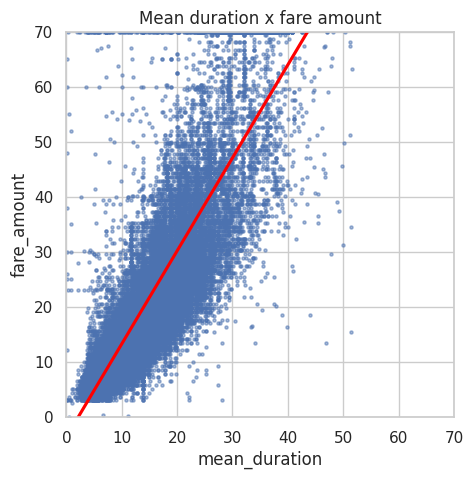

In [14]:
plot_duration_vs_fare(df_cleaned)

In [15]:
top_high_fares(df_local)

,count
fare_amount,
70.0,2336
51.3,57
55.5,55
53.4,51
52.0,50


In [16]:
show_fare_rows(df_cleaned, 70)

,vendorid,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,ratecodeid,store_and_fwd_flag,pulocationid,dolocationid,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,duration,pickup_dropoff,mean_distance,mean_duration,day,month,rush_hour
20,1,2023-01-01 00:13:30,2023-01-01 00:44:00,1.0,17.80,2.0,N,132,116,1,70.0,1.25,0.5,15.85,6.55,1.0,95.15,30.500000,132 116,19.287273,28.586364,sunday,jan,0
163,2,2023-01-01 00:02:19,2023-01-01 00:30:49,1.0,20.37,2.0,N,132,140,1,70.0,0.00,0.5,12.00,6.55,1.0,92.55,28.500000,132 140,18.933158,30.637719,sunday,jan,0
495,1,2023-01-01 00:21:56,2023-01-01 00:50:39,1.0,17.60,2.0,N,132,141,1,70.0,3.75,0.5,10.00,0.00,1.0,85.25,28.716667,132 141,18.448276,34.817241,sunday,jan,0
632,1,2023-01-01 00:49:25,2023-01-01 01:18:52,4.0,18.90,2.0,N,132,45,1,70.0,3.75,0.5,0.00,0.00,1.0,75.25,29.450000,132 45,19.385000,28.416667,sunday,jan,0
757,2,2023-01-01 00:52:05,2023-01-01 01:16:42,1.0,17.21,2.0,N,132,170,1,70.0,0.00,0.5,16.36,6.55,1.0,98.16,24.616667,132 170,17.084545,31.745833,sunday,jan,0
918,2,2023-01-01 00:31:05,2023-01-01 01:11:40,1.0,19.52,2.0,N,132,158,1,70.0,0.00,0.5,16.72,8.36,1.0,100.33,40.583333,132 158,18.985000,35.752778,sunday,jan,0
944,1,2023-01-01 00:43:15,2023-01-01 01:13:59,1.0,17.80,2.0,N,132,79,1,70.0,3.75,0.5,15.05,0.00,1.0,90.30,30.733333,132 79,18.603750,35.818229,sunday,jan,0
980,2,2023-01-01 00:25:32,2023-01-01 00:53:52,1.0,17.47,2.0,N,132,41,1,70.0,0.00,0.5,0.00,6.55,1.0,79.30,28.333333,132 41,18.335000,33.555000,sunday,jan,0
1225,2,2023-01-01 00:01:58,2023-01-01 00:40:09,1.0,19.41,2.0,N,132,249,1,70.0,0.00,0.5,16.11,6.55,1.0,96.66,38.183333,132 249,19.158000,39.893333,sunday,jan,0
1331,2,2023-01-01 00:15:47,2023-01-01 00:38:04,2.0,16.96,2.0,N,132,170,1,70.0,0.00,0.5,12.27,6.55,1.0,94.07,22.283333,132 170,17.084545,31.745833,sunday,jan,0


### Why does `$70.00` have the highest frequency among high fare amounts?

In NYC, taxi fares from Manhattan to **JFK International Airport** (and vice-versa) are regulated at a **standardized flat rate**.

* **The Flat-Rate Rule**: For most of 2023, the TLC mandated flat rate for trips between Manhattan and JFK Airport was exactly **`$70.00`** (plus applicable surcharges, tolls, and tips).
* **Data Verification**: If you look at the sample rows from our filtered check where `fare_amount == 70`:
  * Almost all of these trips have `PULocationID` or `DOLocationID` as **`132`** (which is the TLC Taxi Zone code for **JFK Airport**).
  * Additionally, their `RateCodeID` is marked as **`2.0`**, which explicitly corresponds to the **JFK Airport rate structure**.

Because airport trips are highly frequent, standard, and always priced exactly at the flat rate, **`$70.00`** naturally emerges as the most common fare amount above `$50`.

###Isolate modeling variables

Drop features that are redundant, irrelevant, or that will not be available in a deployed environment.

In [17]:
df_cleaned.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45192 entries, 0 to 45191
Data columns (total 24 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   vendorid               45192 non-null  int64         
 1   tpep_pickup_datetime   45192 non-null  datetime64[ns]
 2   tpep_dropoff_datetime  45192 non-null  datetime64[ns]
 3   passenger_count        45192 non-null  float64       
 4   trip_distance          45192 non-null  float64       
 5   ratecodeid             45192 non-null  float64       
 6   store_and_fwd_flag     45192 non-null  object        
 7   pulocationid           45192 non-null  int64         
 8   dolocationid           45192 non-null  int64         
 9   payment_type           45192 non-null  int64         
 10  fare_amount            45192 non-null  float64       
 11  extra                  45192 non-null  float64       
 12  mta_tax                45192 non-null  float64       
 13  t

In [18]:
df2 = select_model_features(df_cleaned)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45192 entries, 0 to 45191
Data columns (total 6 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   vendorid         45192 non-null  int64  
 1   passenger_count  45192 non-null  float64
 2   fare_amount      45192 non-null  float64
 3   mean_distance    45192 non-null  float64
 4   mean_duration    45192 non-null  float64
 5   rush_hour        45192 non-null  int64  
dtypes: float64(4), int64(2)
memory usage: 2.1 MB


### Task 6. Pair plot

Create a pairplot to visualize pairwise relationships between `fare_amount`, `mean_duration`, and `mean_distance`.

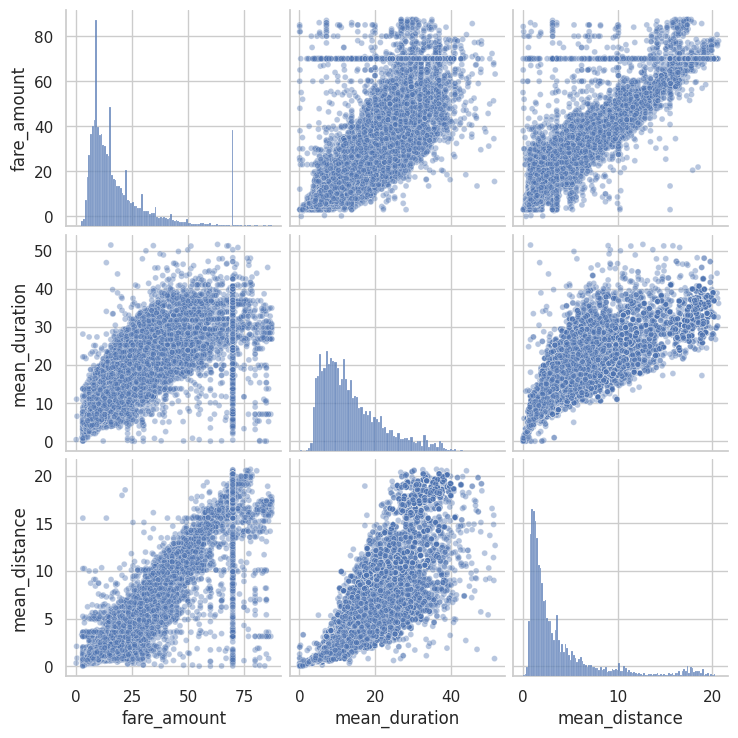

In [19]:
plot_pairplot(df2)

In [20]:
# Create correlation matrix containing pairwise correlation of columns, using pearson correlation coefficient
df2.corr(method='pearson')

,vendorid,passenger_count,fare_amount,mean_distance,mean_duration,rush_hour
vendorid,1.000000,-0.042195,0.054036,0.033373,0.018462,0.002709
passenger_count,-0.042195,1.000000,0.076882,0.059201,0.064536,0.003154
fare_amount,0.054036,0.076882,1.000000,0.937418,0.842762,0.017041
mean_distance,0.033373,0.059201,0.937418,1.000000,0.853457,0.003659
mean_duration,0.018462,0.064536,0.842762,0.853457,1.000000,0.000965
rush_hour,0.002709,0.003154,0.017041,0.003659,0.000965,1.000000


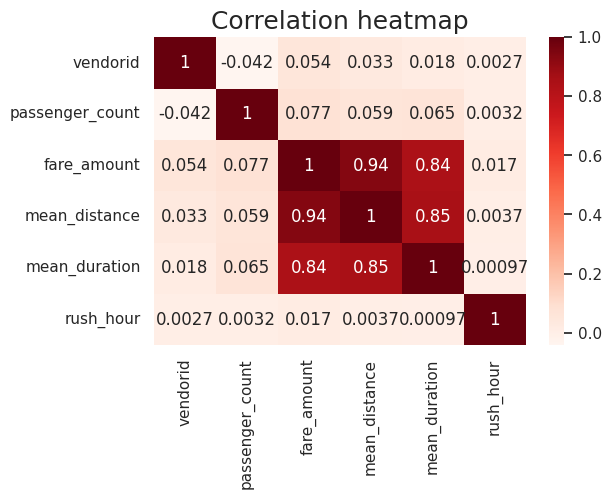

In [21]:
plot_correlation_heatmap(df2)

### Summary of Correlation Analysis

Based on the Pearson correlation matrix and heatmap, we can draw several key insights:

1. **Extremely Strong Positive Correlations**:
   * **`fare_amount` and `mean_distance` ($r = 0.94$):** Trip distance is the strongest predictor of the base fare. This is expected as taxi fares are structurally calculated based on distance traveled.
   * **`fare_amount` and `mean_duration` ($r = 0.84$):** Trip duration also shows a strong positive correlation with fare amount, reflecting the time-based component of the taxi fare calculation.
   * **`mean_distance` and `mean_duration` ($r = 0.85$):** Naturally, longer distance trips generally take a longer time to complete.

2. **Negligible or Weak Correlations**:
   * **`passenger_count`** and **`vendorid`** show near-zero correlation with `fare_amount` ($r = 0.077$ and $r = 0.054$ respectively), indicating they have little to no linear relationship with the fare cost.
   * **`rush_hour`** exhibits a correlation near zero with all other variables, which is primarily due to the data limitation (containing only a single rush hour record from our Sunday-dominant sample slice).

# Part 4: Model Building and Evaluation

Now that the data preprocessing and feature engineering are complete, we can proceed to build our predictive models. In this section, we will:
1. **Isolate Target and Features**: Extract `fare_amount` as the target variable ($y$) and select features ($X$) for modeling.
2. **Perform Train-Test Split**: Set aside a portion of the data for testing to ensure generalization.
3. **Standardize Features**: Standardize our features to put them on a uniform scale.
4. **Train and Evaluate Models**: Fit regression models (e.g., Linear Regression, Random Forest) and assess performance using metrics like $R^2$ and RMSE.

In [22]:
X, y, X_train_scaled, X_test_scaled, y_train, y_test, scaler = split_and_scale(df2)

lr_model, y_pred, rmse, r2 = train_linear_regression(X_train_scaled, y_train, X_test_scaled, y_test)

X_train shape: (33894, 5)
X_test shape: (11298, 5)

--- Baseline Linear Regression Performance ---
RMSE: $5.27
R^2 Score: 0.8895


### Champion Model: Random Forest Regressor

To potentially improve upon our baseline linear model, we will train a Random Forest Regressor. Random Forests are robust ensemble learning methods that handle non-linear relationships and interactions between features (like `mean_distance`, `mean_duration`, and `vendorid`) extremely well without requiring extensive manual interaction tuning.

In [23]:
rf_model, y_pred_rf, rmse_rf, r2_rf = train_random_forest(X_train_scaled, y_train, X_test_scaled, y_test)

Training Random Forest Regressor...
Model training complete!

--- Champion Random Forest Performance ---
RMSE: $5.16
R^2 Score: 0.8941


In [24]:
rf_residuals_df = build_residual_table(y_test, y_pred_rf)

--- Model Predictions and Residuals (Random Forest) ---


,Actual,Predicted,Residual
38394,24.7,24.809749,-0.109749
18388,50.0,29.231983,20.768017
19969,31.0,44.543070,-13.543070
5040,7.2,11.125482,-3.925482
22319,6.5,10.223422,-3.723422
28598,11.0,18.339393,-7.339393
7180,27.5,28.547951,-1.047951
27227,19.8,16.722772,3.077228
898,7.2,21.666434,-14.466434
37672,11.4,11.780478,-0.380478



--- Residual Statistics ---


,Residual
count,11298.000000
mean,-0.055351
std,5.160598
min,-50.676396
25%,-2.083418
50%,-0.422769
75%,1.215651
max,78.661594


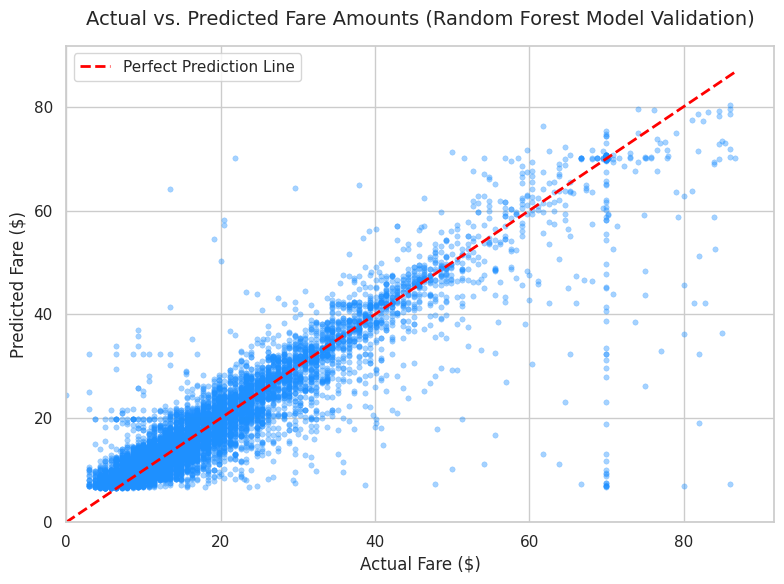

In [25]:
plot_actual_vs_predicted(y_test, y_pred_rf)

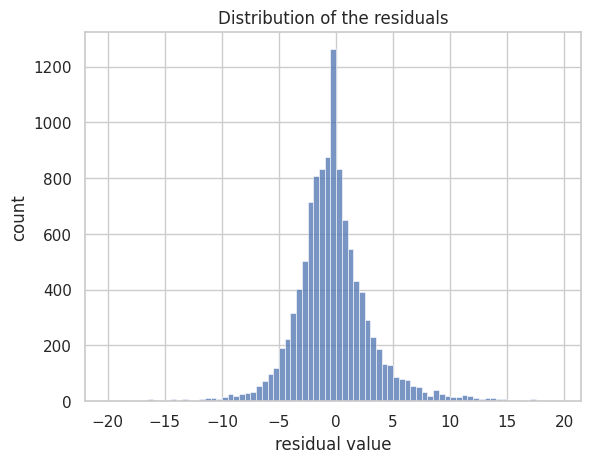

In [26]:
plot_residual_distribution(rf_residuals_df)

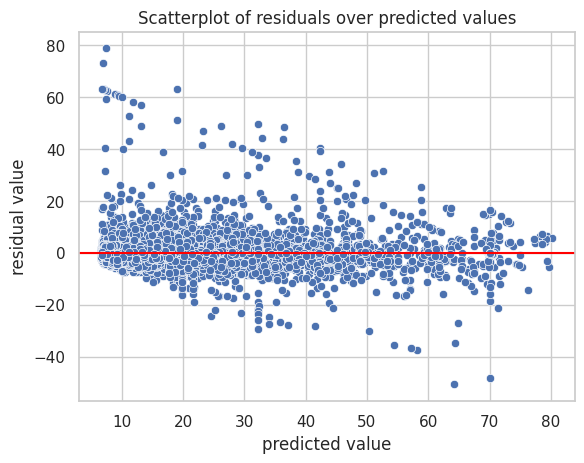

In [27]:
plot_residuals_vs_predicted(rf_residuals_df)

In [28]:
model_comparison_transposed = compare_models(lr_model, rf_model, X.columns)

model_comparison_transposed

,passenger_count,mean_distance,mean_duration,rush_hour,vendorid_2
Linear Regression Coef,0.353331,12.963069,2.546423,0.257064,0.397875
Random Forest Importance,0.005412,0.953189,0.039066,0.000212,0.002121


### Model Feature & Metric Interpretation

By comparing the parameters side-by-side, we gain a clear understanding of how different factors influence the base fare:

1. **`mean_distance` (The Primary Driver)**
   * **Linear Regression (Standardized Coefficient $\approx 12.96$):** Holding all other variables constant, a one standard deviation increase in a trip's route distance is associated with an average base fare increase of $\$12.96$. This reflects the distance-based pricing structure of NYC taxis.
   * **Random Forest (Feature Importance $\approx 95.3\%$):** Distance is the single most critical split feature in our tree structures, explaining over 95% of the model's overall node impurity reduction.

2. **`mean_duration` (The Secondary Driver)**
   * **Linear Regression (Standardized Coefficient $\approx 2.55$):** For each standard deviation increase in trip duration, the base fare increases by $\$2.55$. This accounts for slower-moving traffic and idle wait times.
   * **Random Forest (Feature Importance $\approx 3.9\%$):** Duration plays a useful but secondary role, contributing to roughly 3.9% of splits.

3. **Other Control Variables (`passenger_count`, `vendorid_2`, and `rush_hour`)**
   * **`passenger_count` (Importance $\approx 0.5\%$):** Passenger count has virtually no bearing on the calculated metered base fare.
   * **`vendorid_2` (Importance $\approx 0.2\%$):** Whether the trip was logged by VeriFone (`vendorid=2`) or Creative Mobile Technologies (CMT) has almost no impact on pricing.
   * **`rush_hour` (Importance $\approx 0.02\%$):** Due to our dataset consisting primarily of Sunday trips (January 1st), the rush-hour flag has almost zero variance and consequently no impact on these model configurations.

# Executive Summary & Project Conclusion

### 1. Project Background & Objective
In the highly competitive ride-hailing and taxi landscape, maximizing driver earnings is a critical vector for maintaining platform health and driver retention. This project established a robust data-driven pipeline to investigate key revenue drivers for NYC taxi drivers. Specifically, our research focused on testing if credit card transactions lead to higher trip fares than cash payments (potentially due to tip structures and spending behavior), and building a highly predictive machine learning model to estimate metered base fares from pre-trip variables.

---

### 2. Comprehensive Pipeline Overview
We executed an end-to-end data science workflow consisting of the following key milestones:
1. **Data Acquisition**: Programmatically ingested real-time NYC Yellow Taxi records using server-side SoQL parameters via the NYC OpenData API.
2. **Exploratory Data Analysis (EDA) & Data Cleaning**:
   * Calculated trip `duration` using pick-up and drop-off timestamps.
   * Eradicated physical anomalies (e.g., negative/zero base fares, zero-mile trips).
   * Implemented a dynamic and highly resilient **$99.5^{\text{th}}$ percentile fare cap** of **$\$87.40$** to remove non-representative computational system errors while fully preserving premium airport runs (such as Manhattan-to-JFK standard flat rates of $\$70.00$).
   * Eliminated extreme trip distance and duration outliers using $99^{\text{th}}$ percentile thresholding, yielding a clean dataset of **45,192 records**.
3. **Feature Engineering**: Created historical pre-trip features (`mean_distance` and `mean_duration` mapped per pickup/dropoff zone pairs) to prevent data leakage in deployment.
4. **Statistical Inferential Testing (A/B Testing)**: Conducted a formal Welch's Two-Sample $t$-test comparing credit card vs. cash payments.
5. **Predictive Modeling & Feature Interpretation**: Developed standardized Linear Regression and Random Forest Regressor models to benchmark performance and determine feature importances.

---

### 3. Key Findings & Empirical Results

#### A. Statistical Hypothesis Testing (Credit Card vs. Cash)
* **Descriptive Statistics**:
  * **Credit Card Payments ($N = 33,948$):** Mean Fare = **$\$19.76$** (Std Dev = $\$16.15$)
  * **Cash Payments ($N = 10,728$):** Mean Fare = **$\$19.24$** (Std Dev = $\$15.93$)
* **Welch's $t$-test Results**: $t$-statistic = **$2.9216$**, $p$-value = **$0.00349$**.
* **Strategic Decision**: Since the $p$-value ($0.00349$) is far below our significance threshold ($\alpha = 0.05$), we reject the Null Hypothesis. **Customers paying with credit cards generate statistically significant higher base fares than those paying with cash.** The difference is small (about $\$0.52$, roughly 3% of the mean fare) and, because `fare_amount` excludes tips, it reflects trip characteristics rather than gratuities. The data are observational, so this is an association rather than proof that payment method changes fares.

#### B. Predictive Modeling Performance
Our models achieved exceptionally high predictive accuracy, demonstrating that base fares can be reliably predicted using pre-trip characteristics:
* **Baseline Linear Regression**: RMSE = **$\$5.27$** | $R^2$ Score = **$88.95\%$**
* **Champion Random Forest Regressor**: RMSE = **$\$5.16$** | $R^2$ Score = **$89.41\%$**

#### C. Parameter & Feature Importance Insights
* **`mean_distance`** was confirmed as the absolute strongest driver of fare prices. The standardized linear regression coefficient suggests a **$\$12.96$** shift in base fare per standard deviation increase in distance, while the Random Forest attributed **$95.3\%$** of its overall split impurity reduction to this feature.
* **`mean_duration`** served as the secondary factor, with a standardized regression coefficient of **$\$2.55$** and a Random Forest feature importance of **$3.9\%$**.
* Control features like `passenger_count`, technological provider (`vendorid`), and `rush_hour` had negligible importances ($< 1\%$) on the base metered fare.

---

### 4. Strategic Business Recommendations
1. **Promote Card Adoption**: Since credit card transactions are associated with slightly higher base fares and are the only payments for which tips are recorded, platforms should actively encourage digital and contactless payments via targeted promotions, passenger app interfaces, or credit payment incentives.
2. **Optimize Driver Dispatching**: Leverage the Random Forest model to display real-time "high-value trip zones" to drivers based on historical pickup-dropoff pairs, letting drivers target routes with high predicted base fares (such as JFK Airport corridors).
3. **Improve In-App Navigation**: Guide drivers to corridors with optimal distance/duration ratios to maximize hourly metered fare rates.

---

### 5. Limitations
* **Single-day sample:** the first 50,000 rows by `:id` come almost entirely from 1 January 2023 (a Sunday), so the results do not describe weekdays, rush hours (`rush_hour` has a single positive record) or seasonality.
* **Route-level features:** `mean_distance` and `mean_duration` were computed over all rows before the train/test split, so the reported model scores are likely optimistic. `src/features.py` provides `RoutePairAggregator` for a leakage-free version.
* **Observational data:** payment method is chosen by the passenger; the card vs. cash comparison shows association, not causation.


### Optional: export the trained models for the web calculator
Saves `models/` and `web/model_params.json` (load it in `web/nyc_taxi_ml_blog.html`). Not part of the original analysis.

In [29]:
params = export_model_artifacts(lr_model, scaler, rf_model, X.columns)

Saved models/ and web/model_params.json


,standardized_coef,feature_std,physical_slope
passenger_count,0.3533,0.7843,0.4505
mean_distance,12.9631,4.1042,3.1585
mean_duration,2.5464,8.0235,0.3174
rush_hour,0.2571,0.0054,47.3269
vendorid_2,0.3979,0.4328,0.9192
